# Fase 5 — Avaliação e Deploy

## 1. Avaliação dos modelos com base no custo de negócio

Nesta etapa, vamos avaliar os modelos **Decision Tree** e **XGBoost** considerando o impacto financeiro dos erros de classificação.

Os custos definidos são:

- **Falso Negativo (FN): R$ 5.000**
  - Aprovamos um cliente que se tornou inadimplente.
  - Representa a perda do principal emprestado.

- **Falso Positivo (FP): R$ 500**
  - Negamos crédito para um cliente que pagaria.
  - Representa a perda da margem potencial desse cliente.

O objetivo é testar diferentes limiares de probabilidade e identificar, para cada modelo, o limiar que **minimiza o custo total de decisão**.

Custo Total = (FN × 5.000) + (FP × 500)

In [3]:
# ============================================================
# 2. Configuração do projeto e importações
# ============================================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier

from xgboost import XGBClassifier


# Raiz do projeto
PROJECT_ROOT = Path.cwd().parent

# Pasta que contém o pacote consumer_credit_risk
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))


print("Raiz do projeto:", PROJECT_ROOT)
print("Pasta src:", SRC_DIR)

Raiz do projeto: /home/dropa/projetos/consumer_credit_risk
Pasta src: /home/dropa/projetos/consumer_credit_risk/src


In [4]:
# ============================================================
# 3. Carregamento dos dados e separação treino/teste
# ============================================================

from sklearn.model_selection import train_test_split

from consumer_credit_risk.data import CREDIT_DATA_FILE


# Carregar a base
df = pd.read_csv(CREDIT_DATA_FILE)

# Separar variáveis explicativas e alvo
X = df.drop(columns="inadimplente_2anos")
y = df["inadimplente_2anos"]


# Reproduzir exatamente a divisão usada na preparação/modelagem
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


print("Base completa:", df.shape)
print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)

print("\nTaxa de inadimplência:")
print(f"Base completa: {y.mean():.4f}")
print(f"Treino:        {y_treino.mean():.4f}")
print(f"Teste:         {y_teste.mean():.4f}")

Base completa: (150000, 11)
Treino: (112500, 10)
Teste: (37500, 10)

Taxa de inadimplência:
Base completa: 0.0668
Treino:        0.0668
Teste:         0.0668


In [5]:
# ============================================================
# 4. Pré-processamento
# ============================================================

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

from consumer_credit_risk.preprocessing import preparar_dados_credito


# Colunas que recebem imputação pela mediana
colunas_imputacao = [
    "renda_mensal",
    "dependentes",
    "renda_por_dependente",
    "sobra_caixa",
]


# Transformações definidas no projeto
preparo = FunctionTransformer(
    preparar_dados_credito,
    validate=False
)


# Imputação dos valores ausentes
imputacao = ColumnTransformer(
    transformers=[
        (
            "imputer_mediana",
            SimpleImputer(strategy="median"),
            colunas_imputacao,
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

In [6]:
# ============================================================
# 5. Modelos selecionados para avaliação de custo
# ============================================================

modelos_avaliacao = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.10,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )
}


# Construção e treinamento dos pipelines
pipelines_avaliacao = {}

for nome, modelo in modelos_avaliacao.items():

    pipeline = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", modelo),
        ]
    )

    pipeline.fit(X_treino, y_treino)

    pipelines_avaliacao[nome] = pipeline


print("Modelos treinados:")
for nome in pipelines_avaliacao:
    print(f"- {nome}")

Modelos treinados:
- Decision Tree
- XGBoost


In [7]:
# ============================================================
# 6. Função de custo de negócio
# ============================================================

CUSTO_FN = 5000  # aprovamos quem deu calote
CUSTO_FP = 500   # negamos quem pagaria


def calcular_custo(y_real, probabilidades, limiar):
    """
    Calcula o custo total dos erros de classificação
    para um determinado limiar de probabilidade.
    """

    # Converte probabilidades em classes
    y_pred = (probabilidades >= limiar).astype(int)

    # Matriz de confusão
    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Custo total
    custo_total = (fn * CUSTO_FN) + (fp * CUSTO_FP)

    return custo_total, fp, fn

In [8]:
# ============================================================
# 7. Avaliação dos limiares de probabilidade
# ============================================================

resultados_limiares = []

for nome, pipeline in pipelines_avaliacao.items():

    # Probabilidade prevista de inadimplência (classe 1)
    probabilidades = pipeline.predict_proba(X_teste)[:, 1]

    # Testar limiares de 0.01 até 0.99
    for limiar in np.arange(0.01, 1.00, 0.01):

        custo_total, fp, fn = calcular_custo(
            y_teste,
            probabilidades,
            limiar
        )

        resultados_limiares.append({
            "Modelo": nome,
            "Limiar": round(limiar, 2),
            "FP": fp,
            "FN": fn,
            "Custo Total": custo_total
        })


# Transformar os resultados em DataFrame
df_limiares = pd.DataFrame(resultados_limiares)

df_limiares.head(10)

,Modelo,Limiar,FP,FN,Custo Total
0,Decision Tree,0.01,34989,4,17514500
1,Decision Tree,0.02,15084,244,8762000
2,Decision Tree,0.03,15084,244,8762000
3,Decision Tree,0.04,11493,364,7566500
4,Decision Tree,0.05,8700,501,6855000
5,Decision Tree,0.06,8700,501,6855000
6,Decision Tree,0.07,8699,503,6864500
7,Decision Tree,0.08,8494,518,6837000
8,Decision Tree,0.09,3914,932,6617000
9,Decision Tree,0.10,3630,968,6655000


In [9]:
df_limiares[df_limiares["Modelo"] == "XGBoost"].head(10)

,Modelo,Limiar,FP,FN,Custo Total
99,XGBoost,0.01,24853,53,12691500
100,XGBoost,0.02,16645,174,9192500
101,XGBoost,0.03,13150,259,7870000
102,XGBoost,0.04,10890,333,7110000
103,XGBoost,0.05,9229,421,6719500
104,XGBoost,0.06,7934,509,6512000
105,XGBoost,0.07,6878,584,6359000
106,XGBoost,0.08,5931,659,6260500
107,XGBoost,0.09,5186,735,6268000
108,XGBoost,0.10,4528,792,6224000


In [10]:
# ============================================================
# 8. Melhor limiar de cada modelo
# ============================================================

indices_melhores = (
    df_limiares
    .groupby("Modelo")["Custo Total"]
    .idxmin()
)

df_melhores_limiares = (
    df_limiares
    .loc[indices_melhores]
    .sort_values("Custo Total")
    .reset_index(drop=True)
)

df_melhores_limiares

,Modelo,Limiar,FP,FN,Custo Total
0,XGBoost,0.10,4528,792,6224000
1,Decision Tree,0.09,3914,932,6617000


Vale entender o resultado antes de avançarmos. \
No **XGBoost**, com limiar de `0,10`:
$$
4.528(500)+792(5.000)
$$
$$
=2.264.000+3.960.000
=\mathbf{R\$6.224.000}
$$
Na **Decision Tree**, com limiar `0,09`:
$$
3.914(500)+932(5.000)
$$
$$
=1.957.000+4.660.000
=\mathbf{R\$6.617.000}
$$
Portanto, entre esses dois modelos e considerando os limiares de 0,01 a 0,99 testados, o menor custo observado foi **R$ 6.224.000 no XGBoost, com limiar 0,10**. A diferença de custo em relação ao melhor ponto da árvore foi:
$$
6.617.000-6.224.000=\mathbf{R\$393.000}
$$
Isso também mostra por que não usamos automaticamente `0,50`: com um FN custando **10 vezes** um FP, o critério econômico deslocou o ponto de decisão para probabilidades bem menores.

## 9. Resultado da otimização do limiar

Foram avaliados limiares de probabilidade entre **0,01 e 0,99**, com incrementos de 0,01, para os modelos **Decision Tree** e **XGBoost**.

O custo total foi calculado considerando:

- **Falso Negativo (FN): R$ 5.000**
- **Falso Positivo (FP): R$ 500**

A função de custo utilizada foi:

**Custo Total = (FN × R$ 5.000) + (FP × R$ 500)**

Os melhores resultados encontrados foram:

| Modelo | Melhor limiar | FP | FN | Custo mínimo |
|---|---:|---:|---:|---:|
| XGBoost | 0,10 | 4.528 | 792 | R$ 6.224.000 |
| Decision Tree | 0,09 | 3.914 | 932 | R$ 6.617.000 |

O **XGBoost**, utilizando um limiar de decisão de **0,10**, apresentou o menor custo total entre as alternativas avaliadas.

Embora o XGBoost tenha produzido mais falsos positivos que a Decision Tree, apresentou menos falsos negativos. Como o custo de um falso negativo é dez vezes maior que o custo de um falso positivo, essa redução compensou financeiramente o aumento dos falsos positivos.

A diferença entre os menores custos dos dois modelos foi de **R$ 393.000**.

Esse resultado também demonstra que o limiar padrão de **0,50** não deve ser adotado automaticamente. O limiar de decisão deve considerar o impacto econômico dos diferentes tipos de erro.

Com os custos definidos neste projeto, o ponto de menor custo observado para o XGBoost foi:

**Probabilidade ≥ 0,10 → classificar como inadimplente (1)**  
**Probabilidade < 0,10 → classificar como adimplente (0)**

Assim, o **XGBoost com limiar de 0,10** passa a ser a configuração de referência desta análise de custo para as próximas etapas de avaliação e deploy.

### Observação — diferença em relação ao resultado apresentado no curso do Lira

Os resultados obtidos neste projeto apresentaram uma diferença em relação ao exemplo apresentado no curso especificamente para o **XGBoost**.

Neste projeto, o XGBoost foi treinado com a configuração utilizada anteriormente na etapa de modelagem, resultando em:

- **Limiar de menor custo:** 0,10
- **Falsos Negativos (FN):** 792
- **Falsos Positivos (FP):** 4.528
- **Custo mínimo:** R$ 6.224.000

No material do curso, o XGBoost otimizado apresentou:

- **Limiar de menor custo:** 0,59
- **Falsos Negativos (FN):** 750
- **Falsos Positivos (FP):** 4.707
- **Custo mínimo:** R$ 6.103.500

A **Decision Tree apresentou exatamente os mesmos resultados do curso**, com limiar 0,09, 932 falsos negativos, 3.914 falsos positivos e custo mínimo de R$ 6.617.000.

A diferença observada no XGBoost decorre da configuração do modelo. No curso, foi utilizado um **XGBoost ajustado para o desbalanceamento das classes**, calculando a razão entre a quantidade de exemplos da classe 0 e da classe 1 e utilizando essa informação no treinamento por meio do parâmetro `scale_pos_weight`.

Neste projeto, foi mantida a configuração do XGBoost utilizada anteriormente na etapa de modelagem, sem esse ajuste adicional.

Para reproduzir os resultados do curso com maior fidelidade, seria necessário treinar novamente o XGBoost utilizando a configuração otimizada para o desbalanceamento das classes e, posteriormente, repetir a busca pelo limiar de menor custo.

Para fins didáticos e de continuidade do projeto, será mantido o modelo já desenvolvido, registrando-se esta diferença metodológica.

## 10. Interpretabilidade do modelo — SHAP

Após a avaliação dos custos e a definição do XGBoost como modelo de referência, será realizada uma análise de interpretabilidade utilizando **SHAP (SHapley Additive exPlanations)**.

O objetivo é compreender quais variáveis apresentam maior contribuição para as previsões realizadas pelo modelo.

O SHAP atribui a cada variável um valor que representa sua contribuição para a previsão do modelo. Valores SHAP maiores, em magnitude, indicam maior influência da variável sobre as previsões.

Nesta análise serão utilizados os **dados de teste**, preservando o conjunto utilizado para a avaliação final do modelo.

Para obter uma visão resumida da importância global das variáveis, será calculada a média do valor absoluto dos valores SHAP para cada variável e apresentado o ranking das **10 variáveis mais importantes**.

In [11]:
# ============================================================
# 11. Preparação do XGBoost e dos dados para análise SHAP
# ============================================================

import shap

# Recuperar o pipeline do XGBoost já treinado
pipeline_xgb = pipelines_avaliacao["XGBoost"]

# Aplicar aos dados de teste exatamente as mesmas
# transformações utilizadas antes do modelo
X_teste_preparado = pipeline_xgb[:-1].transform(X_teste)

# Recuperar somente o modelo XGBoost treinado
modelo_xgb = pipeline_xgb.named_steps["modelo"]


print("Formato original do teste:", X_teste.shape)
print("Formato após preparação:", X_teste_preparado.shape)

X_teste_preparado.head()

Formato original do teste: (37500, 10)
Formato após preparação: (37500, 15)


,renda_mensal,dependentes,renda_por_dependente,sobra_caixa,idade,uso_limite_rotativo,razao_divida,linhas_credito_abertas,financiamentos_imobiliarios,atrasos_30_59_dias,atrasos_60_89_dias,atrasos_90_mais_dias,renda_estimada,dependentes_estimados,atrasos_96_98
39795,5500.0,1.0,2750.000000,2343.573898,59,1.000000,0.573896,10,2,0,0,0,0,0,0
86079,5400.0,0.0,3333.333333,3571.242739,71,0.111143,2.000000,24,3,0,0,0,1,0,0
134541,5400.0,0.0,3333.333333,3571.242739,42,0.000000,2.000000,11,3,1,0,0,1,0,0
72738,5461.0,0.0,5461.000000,5459.000367,91,0.005666,0.000366,1,0,0,0,0,0,0,0
135945,19700.0,1.0,9850.000000,15244.226184,61,0.043647,0.226181,15,1,0,0,0,0,0,0


In [12]:
# ============================================================
# 12. Análise SHAP — Top 10 variáveis mais importantes
# ============================================================

# Criar o explicador SHAP para o XGBoost
explainer = shap.TreeExplainer(modelo_xgb)

# Calcular os valores SHAP para os dados de teste
shap_values = explainer.shap_values(X_teste_preparado)


# ------------------------------------------------------------
# Calcular a importância global de cada variável
# Média do valor absoluto dos valores SHAP
# ------------------------------------------------------------

importancia_shap = pd.DataFrame({
    "Variavel": X_teste_preparado.columns,
    "Importancia_SHAP": np.abs(shap_values).mean(axis=0)
})


# Selecionar as 10 variáveis mais importantes
top10_shap = (
    importancia_shap
    .sort_values("Importancia_SHAP", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top10_shap.index = top10_shap.index + 1

top10_shap

,Variavel,Importancia_SHAP
1,uso_limite_rotativo,0.824667
2,atrasos_30_59_dias,0.366090
3,atrasos_90_mais_dias,0.321585
4,idade,0.204726
5,atrasos_60_89_dias,0.165805
6,sobra_caixa,0.139048
7,linhas_credito_abertas,0.130863
8,financiamentos_imobiliarios,0.101299
9,razao_divida,0.066489
10,renda_mensal,0.044900


## 13. Resultado da análise SHAP

A análise SHAP foi aplicada ao modelo **XGBoost** utilizando os dados do conjunto de teste após as mesmas etapas de pré-processamento utilizadas durante o treinamento.

Para avaliar a importância global das variáveis, foi calculada a **média dos valores absolutos de SHAP** para cada característica. Dessa forma, o ranking representa quanto cada variável contribuiu, em média, para as previsões realizadas pelo modelo.

As 10 variáveis mais importantes foram:

| Posição | Variável | Importância SHAP |
|---:|---|---:|
| 1 | uso_limite_rotativo | 0,824667 |
| 2 | atrasos_30_59_dias | 0,366090 |
| 3 | atrasos_90_mais_dias | 0,321585 |
| 4 | idade | 0,204726 |
| 5 | atrasos_60_89_dias | 0,165805 |
| 6 | sobra_caixa | 0,139048 |
| 7 | linhas_credito_abertas | 0,130863 |
| 8 | financiamentos_imobiliarios | 0,101299 |
| 9 | razao_divida | 0,066489 |
| 10 | renda_mensal | 0,044900 |

### Interpretação

A variável **uso_limite_rotativo** apresentou a maior importância SHAP, com valor consideravelmente superior às demais variáveis. Isso indica que ela exerce forte influência sobre as previsões realizadas pelo XGBoost.

Também se destacaram as três variáveis relacionadas ao histórico de atrasos:

- atrasos_30_59_dias;
- atrasos_90_mais_dias;
- atrasos_60_89_dias.

Além delas, idade, sobra de caixa, quantidade de linhas de crédito abertas, financiamentos imobiliários, razão da dívida e renda mensal também aparecem entre as características mais relevantes para as decisões do modelo.

É importante destacar que este ranking representa a **magnitude da influência** das variáveis e não sua direção.

Portanto, esta análise permite afirmar quais variáveis mais influenciam o modelo, mas não permite concluir, apenas com este ranking, se valores maiores ou menores de determinada variável aumentam ou reduzem a previsão de inadimplência.

Para analisar também a direção e o comportamento das variáveis, podem ser utilizados gráficos SHAP específicos, como o summary plot.

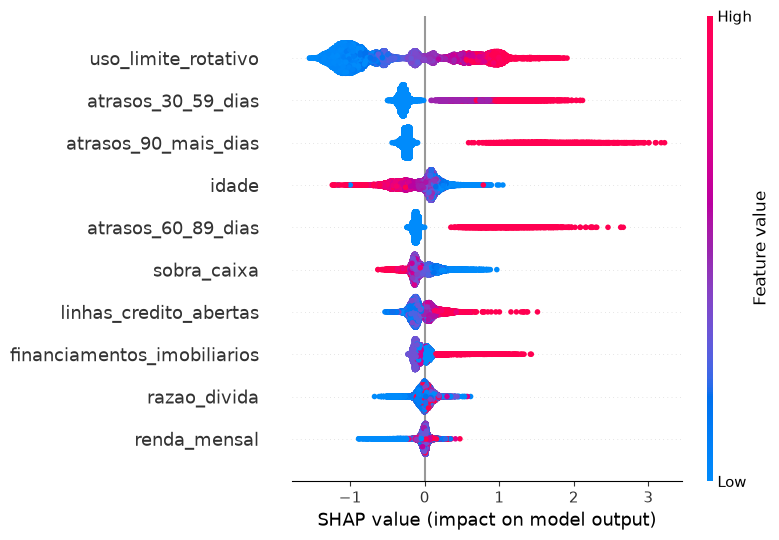

In [13]:
# ============================================================
# 14. SHAP Summary Plot — Top 10 variáveis
# ============================================================

shap.summary_plot(
    shap_values,
    X_teste_preparado,
    max_display=10,
    plot_type="dot"
)

# Fase 6 — Deployment

## 15. Exportação do modelo para produção

Após a modelagem, avaliação de custos e análise de interpretabilidade, o próximo passo é preparar o modelo para utilização em uma aplicação.

O objetivo será desenvolver posteriormente uma aplicação em **Streamlit** na qual um analista de crédito poderá informar os dados de um novo cliente e receber:

1. **Probabilidade estimada de inadimplência**;
2. **Decisão sugerida pelo modelo**;
3. Comparação da probabilidade com o **limiar operacional de 0,10**;
4. Explicação individual da previsão por meio de **SHAP**.

Neste projeto, o modelo utilizado para o deploy será o **XGBoost** já treinado anteriormente.

O limiar operacional definido pela análise de custo foi:

**Limiar = 0,10**

Assim:

- probabilidade de inadimplência < 0,10 → classificação 0;
- probabilidade de inadimplência ≥ 0,10 → classificação 1.

O pipeline completo será salvo, incluindo as etapas de preparação, imputação e o modelo XGBoost treinado.

Dessa forma, novos dados poderão passar exatamente pelo mesmo processo utilizado durante o treinamento, reduzindo o risco de inconsistências entre desenvolvimento e produção.

A função de preparação utilizada pelo pipeline está definida no módulo `consumer_credit_risk.preprocessing`, que também deverá permanecer disponível no ambiente de produção.

In [14]:
# ============================================================
# 16. Exportação do modelo para deploy
# ============================================================

import joblib


# ------------------------------------------------------------
# Modelo vencedor já treinado
# ------------------------------------------------------------

pipeline_final = pipelines_avaliacao["XGBoost"]

# Limiar operacional definido pela análise de custo
LIMIAR_OPERACIONAL = 0.10


# ------------------------------------------------------------
# Informações necessárias para o deploy
# ------------------------------------------------------------

artefato_deploy = {
    "pipeline": pipeline_final,
    "limiar": LIMIAR_OPERACIONAL,
    "modelo": "XGBoost",
    "classe_positiva": 1,
}


# ------------------------------------------------------------
# Caminho para salvar
# ------------------------------------------------------------

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

CAMINHO_MODELO = MODELS_DIR / "modelo_credito_xgb.joblib"


# ------------------------------------------------------------
# Salvar
# ------------------------------------------------------------

joblib.dump(
    artefato_deploy,
    CAMINHO_MODELO
)


print("Modelo salvo com sucesso.")
print("Arquivo:", CAMINHO_MODELO)
print("Limiar operacional:", LIMIAR_OPERACIONAL)

Modelo salvo com sucesso.
Arquivo: /home/dropa/projetos/consumer_credit_risk/models/modelo_credito_xgb.joblib
Limiar operacional: 0.1


In [15]:
# ============================================================
# 17. Validação do artefato salvo
# ============================================================

# Carregar o artefato a partir do disco
artefato_teste = joblib.load(CAMINHO_MODELO)

# Recuperar pipeline e limiar
pipeline_teste = artefato_teste["pipeline"]
limiar_teste = artefato_teste["limiar"]

# Selecionar alguns clientes da base de teste
X_amostra = X_teste.head(5)

# Calcular probabilidades de inadimplência
probabilidades = pipeline_teste.predict_proba(X_amostra)[:, 1]

# Aplicar nosso limiar operacional
decisoes = (probabilidades >= limiar_teste).astype(int)

# Organizar resultado
teste_deploy = pd.DataFrame({
    "Probabilidade_Inadimplencia": probabilidades,
    "Limiar": limiar_teste,
    "Classificacao": decisoes
})

teste_deploy

,Probabilidade_Inadimplencia,Limiar,Classificacao
0,0.086395,0.1,0
1,0.014362,0.1,0
2,0.056592,0.1,0
3,0.004429,0.1,0
4,0.006984,0.1,0


## 18. Validação do artefato de deploy

O artefato do modelo foi salvo em:

`models/modelo_credito_xgb.joblib`

O arquivo contém:

- o pipeline completo de pré-processamento e modelagem;
- o modelo XGBoost já treinado;
- o limiar operacional de 0,10;
- a identificação da classe positiva como inadimplência (`1`).

Após a exportação, o artefato foi novamente carregado a partir do disco e utilizado para gerar probabilidades em uma amostra dos dados de teste.

As probabilidades foram convertidas em classificações utilizando o limiar operacional armazenado no próprio artefato:

- probabilidade < 0,10 → classe 0;
- probabilidade ≥ 0,10 → classe 1.

O teste confirmou que o pipeline exportado consegue receber os dados originais de um cliente, executar internamente as etapas de preparação e imputação e produzir a probabilidade de inadimplência.

Com isso, o artefato está preparado para ser utilizado pela aplicação Streamlit.

A aplicação deverá apresentar:

1. formulário para entrada dos dados do cliente;
2. probabilidade estimada de inadimplência;
3. decisão baseada no limiar operacional de 0,10;
4. explicação individual da previsão utilizando SHAP.